# IPDA — Assignment 2 | German Petrol Prices & Forecast Evaluation

**FH Dortmund · Consolidated final notebook · May 1 – September 30, 2026**


**Contents:** 1. Configuration · 2. Data audit · 3. Station verification · 4. Price reconstruction · 5. Daily/weekly patterns · 6. Forecast audit · 7. Stepwise comparison · 8. Forecast-error methodology · 9. Hourly accuracy · 10. Conclusions & limitations.

> **Important limitation:** Tankerkönig historical price files have `diesel`, `e5`, and `e10`, but no separate **TruckDiesel** observed-price column. The provided forecast files do have `TruckDiesel`. We will visualize its forecasts, but **will not invent a TruckDiesel actual value** or mislabel regular diesel.

## Part 1 — Setup and input paths


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
PRICE_DIR = ROOT / "tankerkoenig-data/prices"
STATION_FILE = ROOT / "tankerkoenig-data/stations/2026/09/2026-09-30-stations.csv"
FORECAST_DIR = ROOT / "data/forecasts/Petrolforecastscsv"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

START_DAY = "2026-05-01"
END_DAY = "2026-09-30"
PLOT_DAY = "2026-08-05"  # change this to another day with forecast coverage
TZ = "Europe/Berlin"

STATION_IDS = {
    "STAR":  "005056ba-7cb6-1ed2-bceb-7966ed5a4d26",
    "HEM":   "e1a15081-24dd-9107-e040-0b0a3dfe563c",
    "SHELL": "86cac7b9-6008-4e6d-9542-f07396ae42bb",
    "ARAL":  "3bfab341-1f1e-49e0-8c32-bc77ca730e57",
}
ID_TO_STATION = {v: k for k, v in STATION_IDS.items()}
FUEL_MAP = {"SuperE10": "e10", "Diesel": "diesel"}

price_files = sorted(PRICE_DIR.rglob("*-prices.csv"))
forecast_files = sorted(FORECAST_DIR.rglob("*.csv"))
if not forecast_files:
    alternate = ROOT / "data/forecasts/extracted"
    forecast_files = sorted(alternate.rglob("*.csv"))
    if forecast_files:
        print("Using forecast fallback:", alternate)
print(f"Price files: {len(price_files)} / expected 153")
print(f"Forecast files: {len(forecast_files)}")
print(f"Station file available: {STATION_FILE.is_file()}")
assert price_files, "No historical price CSVs found. Check PRICE_DIR."
assert STATION_FILE.is_file(), "Station snapshot missing. Check STATION_FILE."
assert forecast_files, "Extract the .7z archive and check FORECAST_DIR."


Price files: 153 / expected 153
Forecast files: 514
Station file available: True


## Part 2 — Historical price data: audit & filter
Load only the four assigned stations, rather than loading all Germany-wide records simultaneously. Because files report **price changes**, a price remains valid until the next recorded change; no new row does **not** mean price is missing.

In [2]:
price_parts = []
for f in price_files:
    daily = pd.read_csv(f)
    price_parts.append(daily.loc[daily["station_uuid"].isin(STATION_IDS.values())].copy())

prices = pd.concat(price_parts, ignore_index=True)
prices["date"] = pd.to_datetime(prices["date"], utc=True).dt.tz_convert(TZ)
prices["station"] = prices["station_uuid"].map(ID_TO_STATION)
prices = prices.sort_values(["station", "date"]).reset_index(drop=True)

print("Historical events:", len(prices))
print("Date range:", prices["date"].min(), "→", prices["date"].max())
display(prices.groupby("station").size().rename("events").to_frame())

quality = []
for fuel in ["diesel", "e5", "e10"]:
    flag = fuel + "change"
    quality.append({
        "fuel": fuel,
        "min_eur": prices[fuel].min(), "max_eur": prices[fuel].max(),
        "zeros": int(prices[fuel].eq(0).sum()),
        "suspicious_nonzero_below_1_or_above_3": int(((prices[fuel] > 0) & (prices[fuel] < 1) | (prices[fuel] > 3)).sum()),
        "change_flag_values": dict(prices[flag].value_counts().sort_index()),
    })
display(pd.DataFrame(quality))
print("Duplicated station/time event rows:", prices.duplicated(["station", "date"]).sum())


Historical events: 10498
Date range: 2026-05-01 00:02:02+02:00 → 2026-09-30 20:11:59+02:00


,events
station,
ARAL,2324
HEM,3296
SHELL,2337
STAR,2541


,fuel,min_eur,max_eur,zeros,suspicious_nonzero_below_1_or_above_3,change_flag_values
0,diesel,1.619,2.629,0,0,"{0: 2886, 1: 7530, 3: 82}"
1,e5,1.789,2.549,0,0,"{0: 3221, 1: 7195, 3: 82}"
2,e10,1.729,2.489,0,0,"{0: 3196, 1: 7220, 3: 82}"


Duplicated station/time event rows: 0


## Part 3 — Identify and verify assigned stations


In [3]:
stations = pd.read_csv(STATION_FILE)
assigned = stations[stations["uuid"].isin(STATION_IDS.values())].copy()
assigned["station"] = assigned["uuid"].map(ID_TO_STATION)
columns = ["station", "uuid", "brand", "name", "street", "house_number", "post_code", "city", "latitude", "longitude"]
display(assigned[columns].sort_values("station"))
assert set(assigned["uuid"]) == set(STATION_IDS.values()), "One or more target station IDs absent from station snapshot."

# Nearby / name-match candidates to review for possible duplicates
keywords = r"Hartweg|Hebewerk|Lütgendortmunder Hellweg|Beverbach"
candidates = stations.loc[
    stations["street"].fillna("").str.contains(keywords, case=False, regex=True)
    | stations["name"].fillna("").str.contains(keywords, case=False, regex=True)
]
display(candidates[["uuid", "brand", "street", "house_number", "post_code", "city"]].drop_duplicates())


,station,uuid,brand,name,street,house_number,post_code,city,latitude,longitude
13875,ARAL,3bfab341-1f1e-49e0-8c32-bc77ca730e57,ARAL,Aral Tankstelle,Lütgendortmunder Hellweg,200/a.d A40,44892,Bochum,51.494022,7.339435
3880,HEM,e1a15081-24dd-9107-e040-0b0a3dfe563c,HEM,"Dortmund, Am Hartweg 175",Am Hartweg,175,44149,Dortmund,51.497066,7.403551
11140,SHELL,86cac7b9-6008-4e6d-9542-f07396ae42bb,Shell,Shell Castrop-Rauxel Hebewerkstr. 25,Hebewerkstr.,25,44581,Castrop-Rauxel,51.601760,7.313718
1572,STAR,005056ba-7cb6-1ed2-bceb-7966ed5a4d26,STAR,star Tankstelle,Hebewerkstraße,18,44581,Castrop-Rauxel,51.600507,7.313701


,uuid,brand,street,house_number,post_code,city
1572,005056ba-7cb6-1ed2-bceb-7966ed5a4d26,STAR,Hebewerkstraße,18,44581,Castrop-Rauxel
3880,e1a15081-24dd-9107-e040-0b0a3dfe563c,HEM,Am Hartweg,175,44149,Dortmund
4263,005056ba-7cb6-1ed2-bceb-5b3749294d18,STAR,Lütgendortmunder Hellweg,23,44388,Dortmund
10431,7a4c5fc2-fe20-4a14-b8e0-7d7c74ae2440,AVIA,Lütgendortmunder Hellweg,135,44388,Dortmund
11140,86cac7b9-6008-4e6d-9542-f07396ae42bb,Shell,Hebewerkstr.,25,44581,Castrop-Rauxel
13875,3bfab341-1f1e-49e0-8c32-bc77ca730e57,ARAL,Lütgendortmunder Hellweg,200/a.d A40,44892,Bochum


## Part 4 — Reconstruct continuous stepwise historical prices

In [4]:
fuel_cols = ["e10", "diesel", "e5"]
start_ts = pd.Timestamp(START_DAY, tz=TZ)
end_exclusive = pd.Timestamp(END_DAY, tz=TZ) + pd.DateOffset(days=1)
hour_grid = pd.date_range(start_ts, end_exclusive, freq="1h", inclusive="left")

def regular_actual(station, fuel, times):
    """Price active at each Berlin-aware timestamp; NaN before first observed event."""
    observations = (prices.loc[prices["station"] == station, ["date", fuel]]
                    .sort_values("date").drop_duplicates("date", keep="last")
                    .set_index("date")[fuel])
    return observations.reindex(observations.index.union(times)).sort_index().ffill().reindex(times)

hourly = []
for station in STATION_IDS:
    frame = pd.DataFrame({"time": hour_grid, "station": station})
    for fuel in fuel_cols:
        frame[fuel] = regular_actual(station, fuel, hour_grid).to_numpy()
    hourly.append(frame)
hourly = pd.concat(hourly, ignore_index=True)
hourly["date"] = hourly["time"].dt.date
hourly["hour"] = hourly["time"].dt.hour
hourly["weekday"] = hourly["time"].dt.day_name()
hourly["month"] = hourly["time"].dt.strftime("%Y-%m")
print("Hourly station observations:", len(hourly))
display(hourly.head())


Hourly station observations: 14688


,time,station,e10,diesel,e5,date,hour,weekday,month
0,2026-05-01 00:00:00+02:00,STAR,NaN,NaN,NaN,2026-05-01,0,Friday,2026-05
1,2026-05-01 01:00:00+02:00,STAR,1.949,2.039,2.009,2026-05-01,1,Friday,2026-05
2,2026-05-01 02:00:00+02:00,STAR,1.949,2.039,2.009,2026-05-01,2,Friday,2026-05
3,2026-05-01 03:00:00+02:00,STAR,1.949,2.039,2.009,2026-05-01,3,Friday,2026-05
4,2026-05-01 04:00:00+02:00,STAR,1.949,2.039,2.009,2026-05-01,4,Friday,2026-05


## Part 5 — Price patterns: daily, weekly & evolution over time


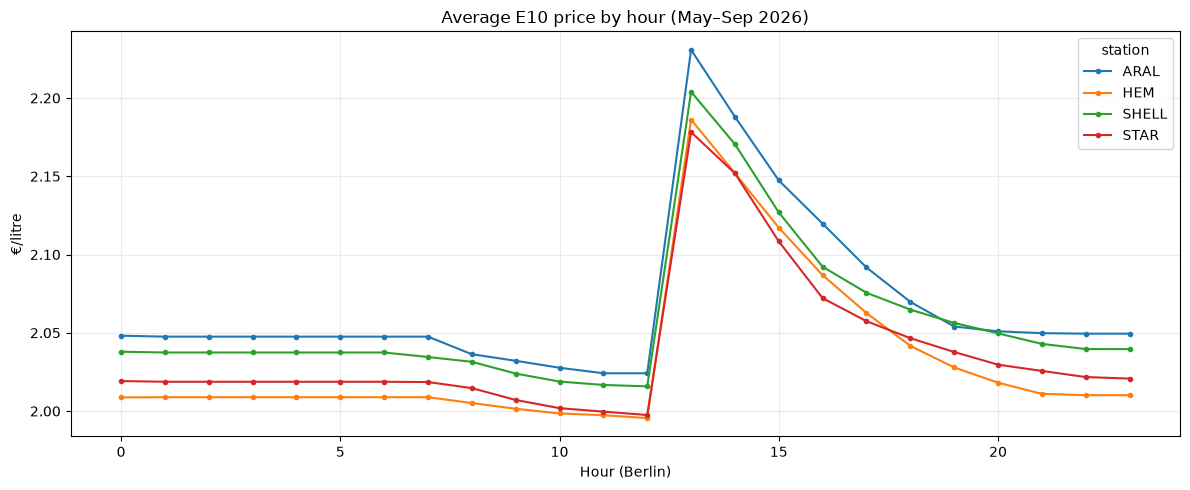

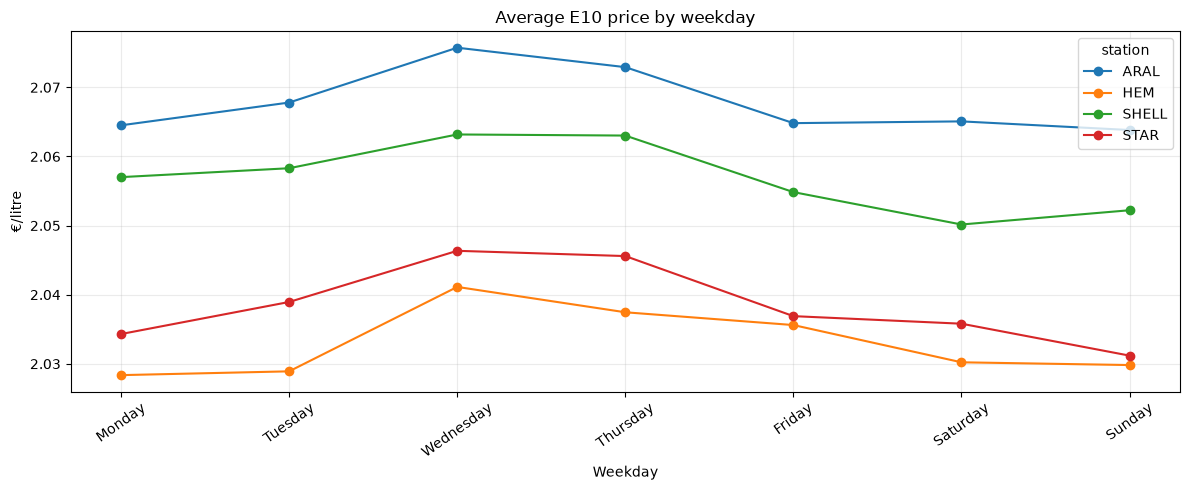

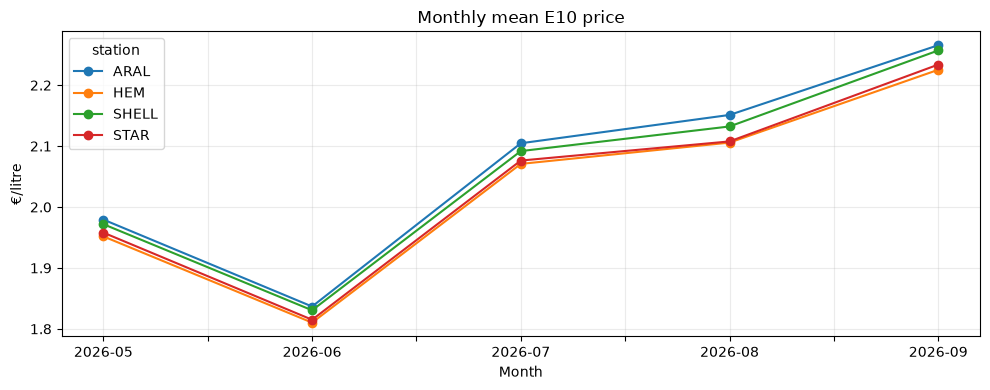

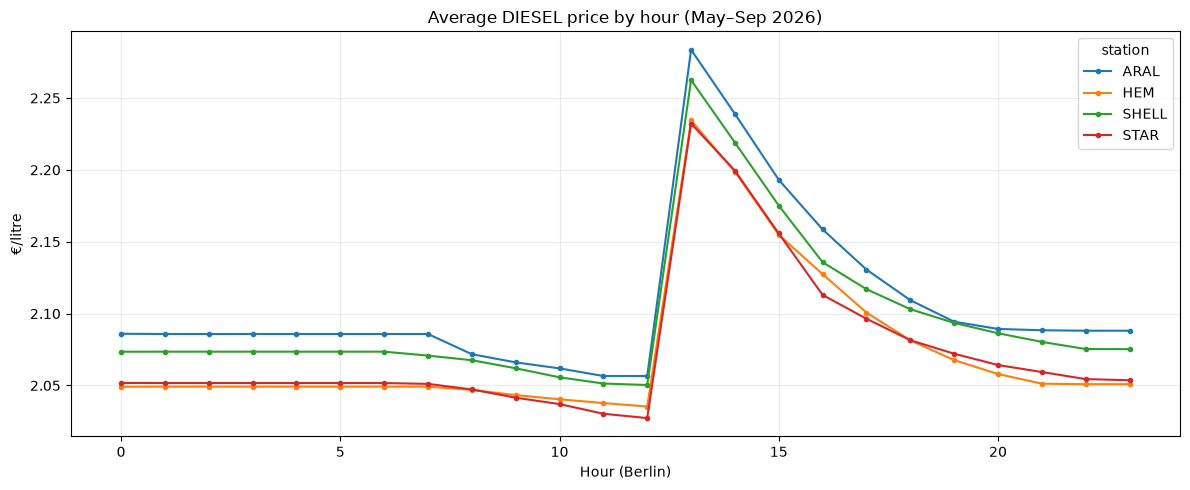

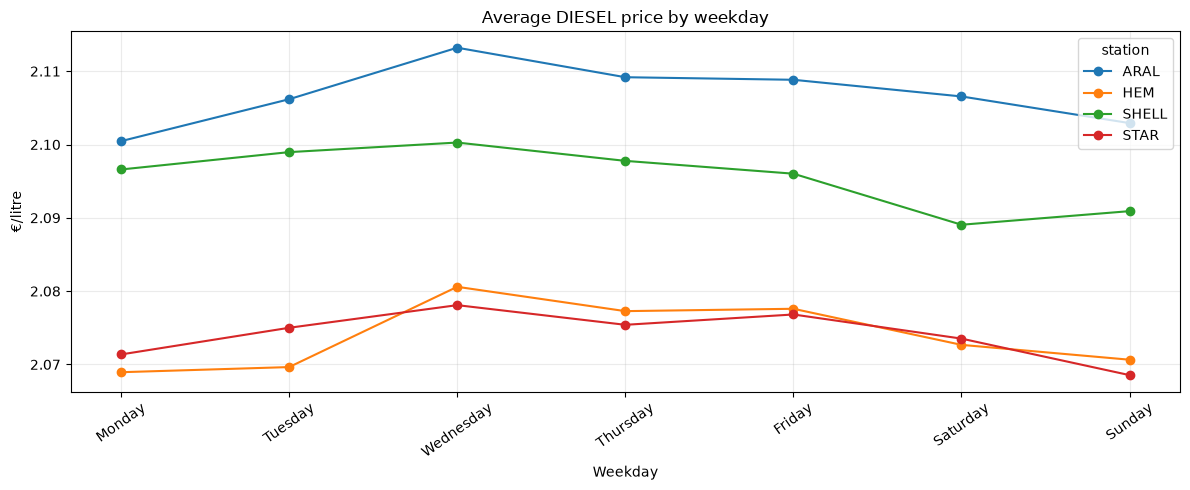

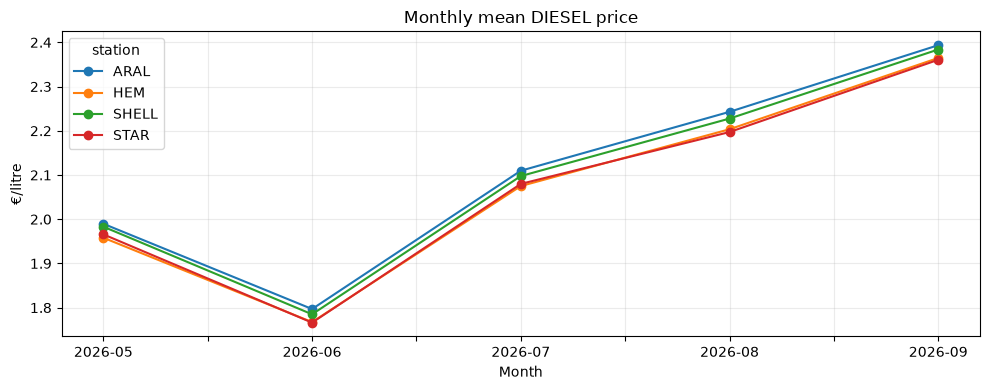

Indicative cheapest/costliest hourly mean; not a guarantee for individual days:


,station,fuel,cheapest_hour,costliest_hour,mean_daily_spread_cents
0,ARAL,e10,11,13,20.89
1,HEM,e10,12,13,19.23
2,SHELL,e10,12,13,19.01
3,STAR,e10,12,13,18.34
4,ARAL,diesel,11,13,22.86
5,HEM,diesel,12,13,20.12
6,SHELL,diesel,12,13,21.56
7,STAR,diesel,12,13,20.84


In [5]:
# Pricing patterns for BOTH fuels, at each of the four stations.
# Sample prices on an hourly grid so every time of day has equal weight.
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

pattern_summaries = []
for fuel in ["e10", "diesel"]:
    hour_profile = hourly.groupby(["station", "hour"])[fuel].mean().unstack("station")
    ax = hour_profile.plot(figsize=(12, 5), marker="o", markersize=3)
    ax.set(title=f"Average {fuel.upper()} price by hour (May–Sep 2026)", xlabel="Hour (Berlin)", ylabel="€/litre")
    ax.grid(alpha=.25)
    plt.tight_layout(); plt.show()

    weekly = (hourly.groupby(["station", "weekday"])[fuel].mean()
              .unstack("station").reindex(weekday_order))
    ax = weekly.plot(figsize=(12, 5), marker="o")
    ax.set(title=f"Average {fuel.upper()} price by weekday", ylabel="€/litre", xlabel="Weekday")
    ax.grid(alpha=.25); plt.xticks(rotation=35); plt.tight_layout(); plt.show()

    monthly = hourly.groupby(["month", "station"])[fuel].mean().unstack("station")
    ax = monthly.plot(figsize=(10, 4), marker="o")
    ax.set(title=f"Monthly mean {fuel.upper()} price", xlabel="Month", ylabel="€/litre")
    ax.grid(alpha=.25); plt.tight_layout(); plt.show()

    daily_stats = hourly.groupby(["station", "date"])[fuel].agg(["min", "max", "mean"]).reset_index()
    daily_stats["daily_spread_cents"] = (daily_stats["max"] - daily_stats["min"]) * 100
    summary = pd.DataFrame({
        "cheapest_hour": hour_profile.idxmin(),
        "costliest_hour": hour_profile.idxmax(),
        "mean_daily_spread_cents": daily_stats.groupby("station")["daily_spread_cents"].mean(),
    })
    summary.insert(0, "fuel", fuel)
    pattern_summaries.append(summary.reset_index().rename(columns={"index":"station"}))

pattern_summary = pd.concat(pattern_summaries, ignore_index=True)
print("Indicative cheapest/costliest hourly mean; not a guarantee for individual days:")
display(pattern_summary.round(2))


**Interpretation guide:** The hourly plots support comparisons of mean low/high price hours, the weekday plots show average weekday differences, and the monthly plots help assess whether pricing levels change. These are descriptive associations rather than causal tests. See the final findings for the original E10 figures; the expanded cell now produces Diesel results too.

## Part 6 — Audit forecast CSV files

In [6]:
usecols = ["station_id", "fuel", "unit", "target_ts_berlin", "retrieved_at_berlin", "price", "min_price", "max_price"]
forecast_parts = []
for i, f in enumerate(forecast_files, start=1):
    raw = pd.read_csv(f, usecols=usecols)
    raw = raw.loc[raw["station_id"].isin(STATION_IDS.values()) & raw["fuel"].isin(["SuperE10", "Diesel", "TruckDiesel"])].copy()
    forecast_parts.append(raw)
forecasts = pd.concat(forecast_parts, ignore_index=True)
forecasts["retrieved_at"] = pd.to_datetime(forecasts["retrieved_at_berlin"], utc=True, errors="coerce").dt.tz_convert(TZ)
forecasts["target_at"] = pd.to_datetime(forecasts["target_ts_berlin"], utc=True, errors="coerce").dt.tz_convert(TZ)
for col in ["price", "min_price", "max_price"]:
    forecasts[col] = pd.to_numeric(forecasts[col], errors="coerce")
print("Forecast units:", forecasts["unit"].value_counts(dropna=False).to_dict())
unit_text = forecasts["unit"].fillna("").astype(str).str.lower()
cent_units = unit_text.str.contains(r"cent|ct/l", regex=True)
for col in ["price", "min_price", "max_price"]:
    forecasts.loc[cent_units, col] = forecasts.loc[cent_units, col] / 100.0
forecasts["station"] = forecasts["station_id"].map(ID_TO_STATION)
forecasts["horizon_hours"] = (forecasts["target_at"] - forecasts["retrieved_at"]).dt.total_seconds() / 3600
forecasts = forecasts.dropna(subset=["retrieved_at", "target_at", "price"])
print("Forecast records:", len(forecasts))
print("Target range:", forecasts["target_at"].min(), "→", forecasts["target_at"].max())
print("Retrieval range:", forecasts["retrieved_at"].min(), "→", forecasts["retrieved_at"].max())
display(forecasts.groupby(["station", "fuel"]).size().unstack(fill_value=0))
display(forecasts.groupby("fuel")[["price", "horizon_hours"]].agg(["min", "median", "max"]))
print("Forecasts with nonpositive horizon:", (forecasts["horizon_hours"] <= 0).sum())
print("Duplicate (station, fuel, retrieval, target):", forecasts.duplicated(["station_id", "fuel", "retrieved_at", "target_at"]).sum())


Forecast units: {'Liter': 759408}
Forecast records: 759408
Target range: 2026-08-05 11:00:00+02:00 → 2026-10-18 23:00:00+02:00
Retrieval range: 2026-08-05 10:50:00.004026+02:00 → 2026-10-12 20:50:00.005128+02:00


fuel,Diesel,SuperE10,TruckDiesel
station,,,
ARAL,79083,79083,79083
HEM,56007,56007,0
SHELL,79083,79083,79083
STAR,57632,57632,57632


price               horizon_hours                       
               min median    max           min     median         max
fuel                                                                 
Diesel       2.072  2.364  2.780     -0.833337  76.166666  159.166666
SuperE10     1.966  2.244  2.535     -0.833337  76.166666  159.166666
TruckDiesel  2.002  2.370  2.784     -0.833337  76.166666  159.166666

Forecasts with nonpositive horizon: 1815
Duplicate (station, fuel, retrieval, target): 0


## Part 7 — Stepwise actual-vs-forecast graphs (4 stations × 3 fuels)

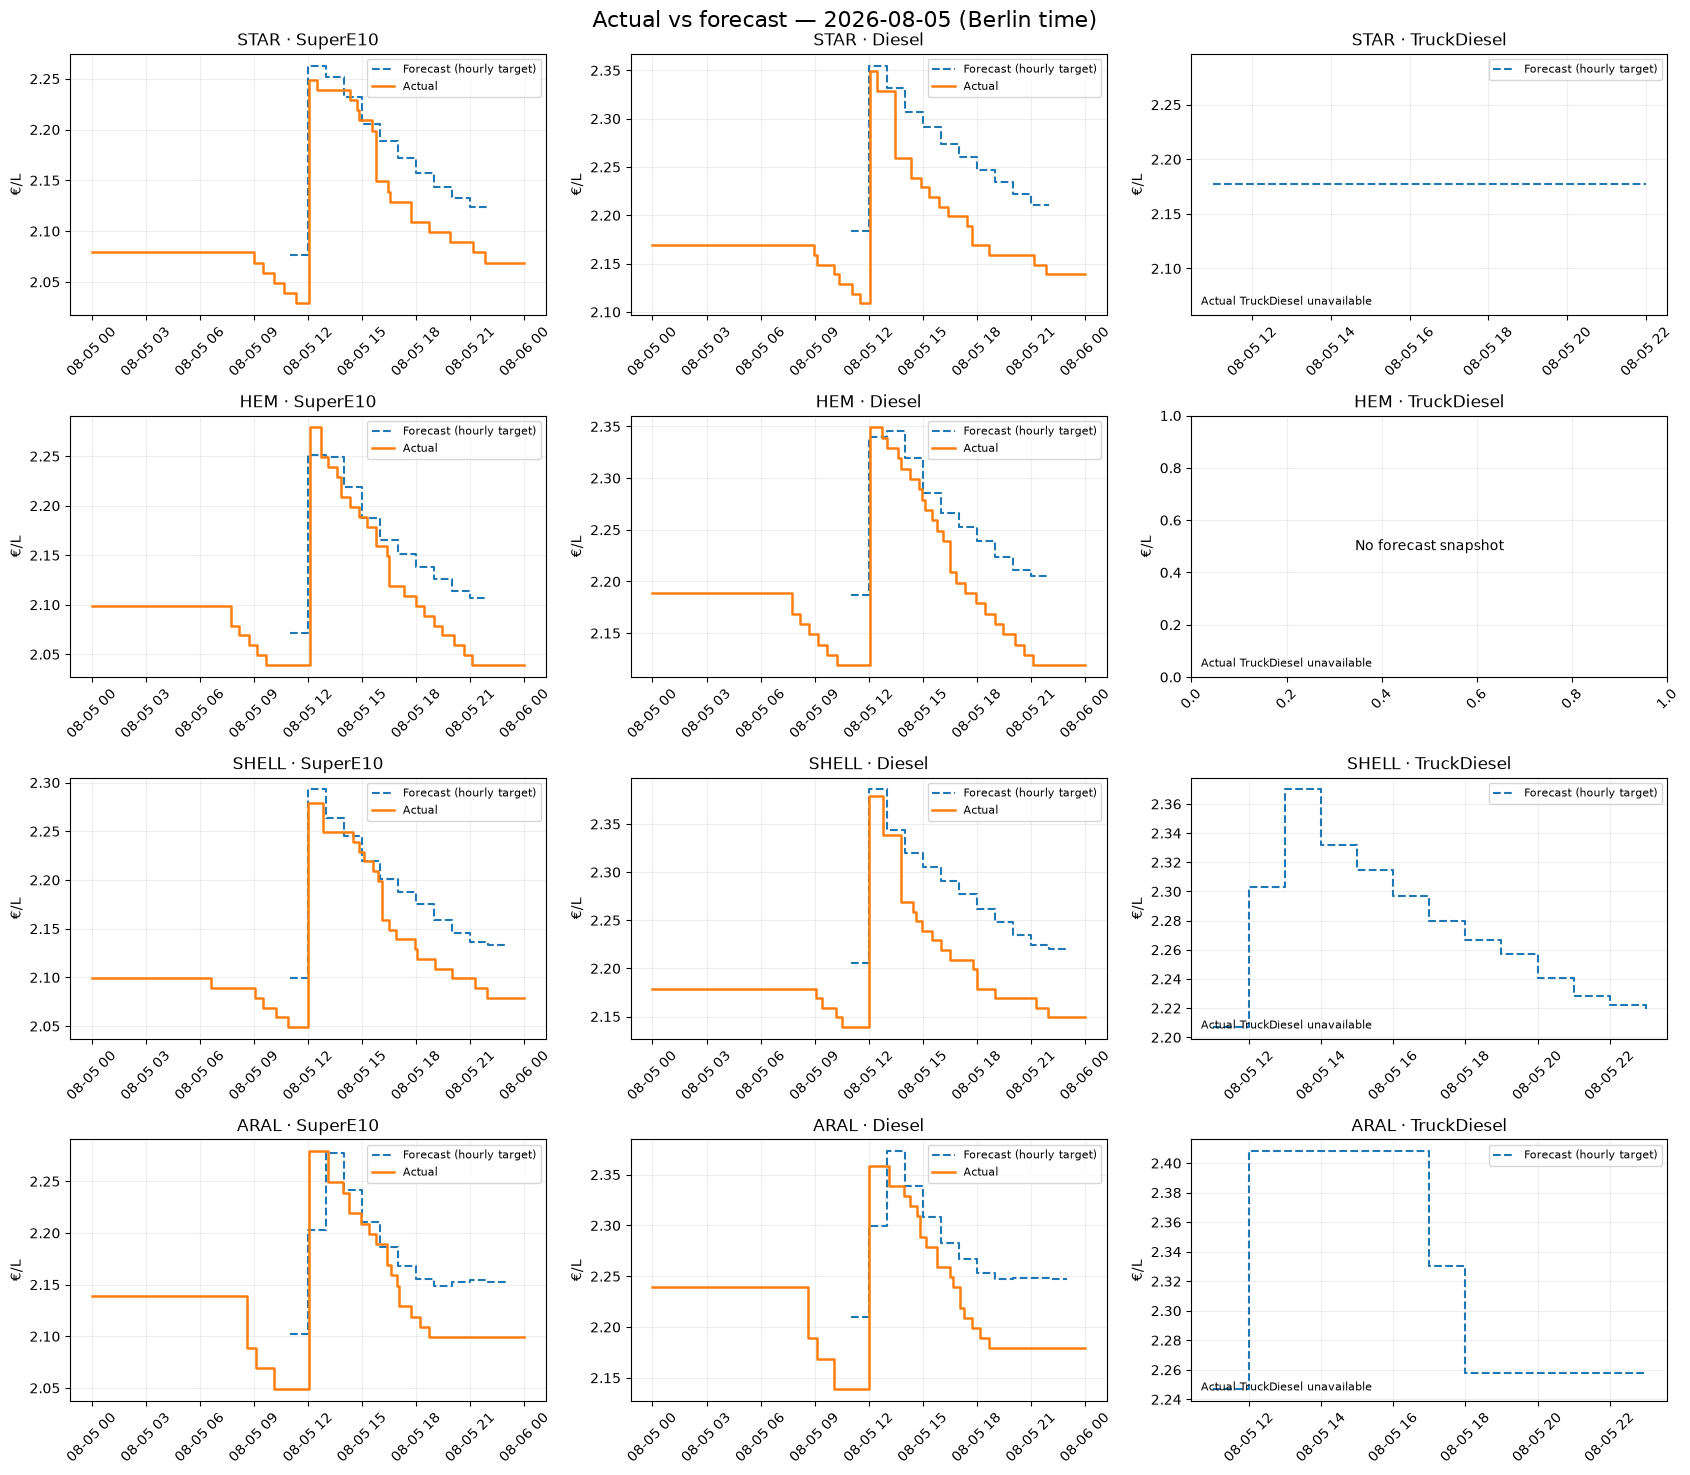

In [7]:
def show_day_forecasts(day=PLOT_DAY):
    d0 = pd.Timestamp(day, tz=TZ)
    d1 = d0 + pd.DateOffset(days=1)
    fig, axes = plt.subplots(4, 3, figsize=(17, 15), sharex=False)
    for r, (station, station_id) in enumerate(STATION_IDS.items()):
        for c, fuel in enumerate(["SuperE10", "Diesel", "TruckDiesel"]):
            ax = axes[r, c]
            available = forecasts.loc[
                (forecasts["station_id"] == station_id) & (forecasts["fuel"] == fuel)
                & forecasts["retrieved_at"].ge(d0) & forecasts["retrieved_at"].lt(d1)
            ]
            if available.empty:
                ax.text(.5, .5, "No forecast snapshot", ha="center", va="center", transform=ax.transAxes)
            else:
                chosen = available["retrieved_at"].min()
                snap = available.loc[(available["retrieved_at"] == chosen)
                     & available["target_at"].ge(chosen)
                     & available["target_at"].lt(d1)].sort_values("target_at")
                if not snap.empty:
                    ax.step(snap["target_at"], snap["price"], where="post", linestyle="--", label="Forecast (hourly target)")
            actual_col = FUEL_MAP.get(fuel)
            if actual_col:
                prior = prices.loc[(prices["station"] == station) & prices["date"].lt(d0), ["date", actual_col]].tail(1)
                within = prices.loc[(prices["station"] == station) & prices["date"].ge(d0) & prices["date"].lt(d1), ["date", actual_col]]
                events = pd.concat([prior, within]).sort_values("date")
                if not events.empty:
                    # Carry forward earlier price to midnight, when known.
                    if not prior.empty:
                        events = pd.concat([pd.DataFrame({"date": [d0], actual_col: [prior.iloc[-1][actual_col]]}), within])
                    events = pd.concat([events, pd.DataFrame({"date": [d1], actual_col: [events.iloc[-1][actual_col]]})])
                    ax.step(events["date"], events[actual_col], where="post", label="Actual", linewidth=1.8)
            else:
                ax.text(.02, .04, "Actual TruckDiesel unavailable", transform=ax.transAxes, fontsize=8)
            ax.set(title=f"{station} · {fuel}", ylabel="€/L")
            ax.grid(alpha=.2)
            ax.tick_params(axis="x", rotation=45)
            handles, labels = ax.get_legend_handles_labels()
            if handles:
                ax.legend(fontsize=8, loc="best")
    fig.suptitle(f"Actual vs forecast — {day} (Berlin time)", fontsize=16)
    fig.tight_layout()
    plt.show()
show_day_forecasts()


## Part 8 — Forecast deviation methodology

**Alternatives:** (a) MAE in cents/L (easy to interpret, preferred); (b) RMSE (penalizes large misses); (c) signed bias (over/underprediction); (d) price-interval coverage if `min_price/max_price` are genuine uncertainty bounds (must be validated).

**Chosen comparable method:** Forecasts have repeated issuance times and horizons. For each unique `(station, fuel, target_at)`, choose the **latest issued prediction from 1–2 hours before the target**; do not mix a 5-minute horizon with a 5-day horizon. Match each target timestamp to the price active at that instant (as-of join on the full 153-day event history). Report missing matches, and compare only SuperE10 and Diesel against historical observations. This defines a clear, repeatable benchmark; change `MIN_HORIZON_H` / `MAX_HORIZON_H` to study alternative horizons.

**Limitations:** Hourly target points do not represent continuously observed prices; time-of-day accuracy means average across hourly *targets*, not full-minute errors. Sparse/uneven available days can bias the overall result. Midnight carry-forward is unknown before the first recorded May 1 event.

In [ ]:
MIN_HORIZON_H = 1.0
MAX_HORIZON_H = 2.0

eligible = forecasts.loc[
    forecasts["fuel"].isin(FUEL_MAP)
    & forecasts["horizon_hours"].between(MIN_HORIZON_H, MAX_HORIZON_H, inclusive="both")
    & forecasts["target_at"].ge(start_ts)
    & forecasts["target_at"].lt(end_exclusive)
].copy()

chosen_fc = (eligible.sort_values("retrieved_at")
             .drop_duplicates(["station_id", "fuel", "target_at"], keep="last")
             .sort_values(["station", "fuel", "target_at"]))

comparison_parts = []
for (station, fuel), pred in chosen_fc.groupby(["station", "fuel"]):
    actual_col = FUEL_MAP[fuel]
    actual_events = (prices.loc[prices["station"].eq(station), ["date", actual_col]]
                     .sort_values("date").rename(columns={"date": "event_at", actual_col: "actual_price"}))
    compare = pd.merge_asof(
        pred.sort_values("target_at"), actual_events,
        left_on="target_at", right_on="event_at", direction="backward"
    )
    comparison_parts.append(compare)

if comparison_parts:
    evaluation = pd.concat(comparison_parts, ignore_index=True).dropna(subset=["actual_price"])
    evaluation["signed_error_cents"] = (evaluation["price"] - evaluation["actual_price"]) * 100
    evaluation["abs_error_cents"] = evaluation["signed_error_cents"].abs()
    evaluation["squared_error_cents2"] = evaluation["signed_error_cents"] ** 2
    evaluation["hour"] = evaluation["target_at"].dt.hour
    evaluation["target_day"] = evaluation["target_at"].dt.date
    evaluation["month"] = evaluation["target_at"].dt.strftime("%Y-%m")
else:
    evaluation = pd.DataFrame()

print("Eligible forecast rows:", len(eligible))
print("Unique target points selected:", len(chosen_fc))
print("Evaluable forecasts with actual prices:", len(evaluation))
if evaluation.empty:
    print("No evaluation matches in this horizon. Inspect horizon distribution in Part 6 and adjust interval.")
else:
    def metric_summary(g):
        return pd.Series({
            "n": len(g),
            "MAE_cents": g["abs_error_cents"].mean(),
            "RMSE_cents": np.sqrt(g["squared_error_cents2"].mean()),
            "bias_cents": g["signed_error_cents"].mean(),
        })
    display(evaluation.groupby(["station", "fuel"]).apply(metric_summary, include_groups=False).round(3))


Eligible forecast rows: 3304
Unique target points selected: 1776
Evaluable forecasts with actual prices: 1776


n  MAE_cents  RMSE_cents  bias_cents
station fuel                                              
ARAL    Diesel    222.0      4.208       5.425      -0.072
        SuperE10  222.0      3.651       4.873       0.152
HEM     Diesel    222.0      5.096       6.861       0.757
        SuperE10  222.0      4.492       6.521       0.764
SHELL   Diesel    222.0      5.142       7.540       0.611
        SuperE10  222.0      4.654       7.089       0.709
STAR    Diesel    222.0      5.429       7.941       0.235
        SuperE10  222.0      4.851       7.183       0.284

## Part 9 — Hourly error pattern and forecast horizon
These plots use **all eligible dates/forecasts**, not just a single 12-point snapshot. A per-hour sample-count table is included so weakly supported hours are visible.

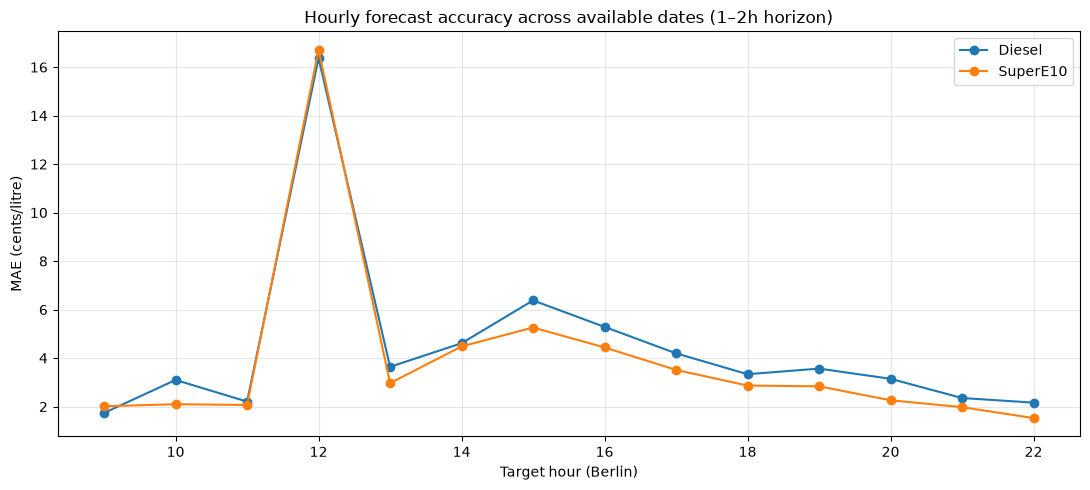

fuel,Diesel,SuperE10
hour,,
9,8,8
10,32,32
11,60,60
12,76,76
13,80,80
14,68,68
15,76,76
16,88,88
17,88,88


fuel,Diesel,SuperE10
station,,
ARAL,4.208,3.651
HEM,5.096,4.492
SHELL,5.142,4.654
STAR,5.429,4.851


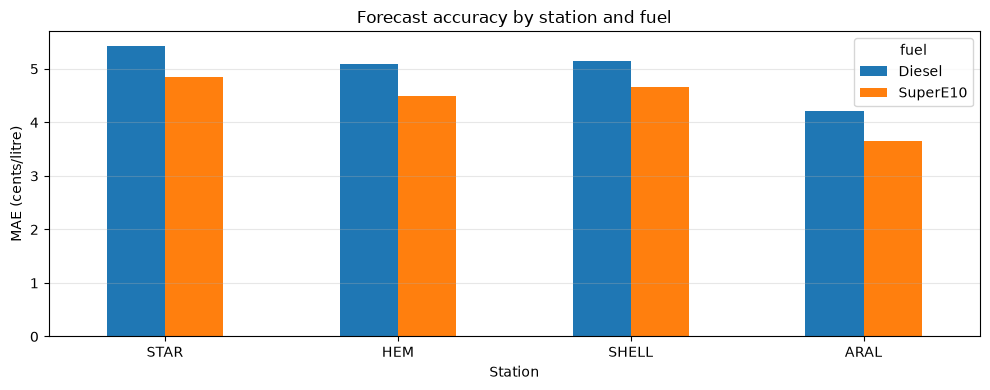

mean  count
month   fuel                     
2026-08 Diesel    6.915625     32
        SuperE10  5.487500     32
2026-09 Diesel    4.896028    856
        SuperE10  4.371846    856

In [9]:
if not evaluation.empty:
    hourly_error = (evaluation.groupby(["fuel", "hour"])
                    .agg(MAE_cents=("abs_error_cents", "mean"), n=("abs_error_cents", "size"))
                    .reset_index())
    fig, ax = plt.subplots(figsize=(11, 5))
    for fuel, grp in hourly_error.groupby("fuel"):
        ax.plot(grp["hour"], grp["MAE_cents"], marker="o", label=fuel)
    ax.set(xlabel="Target hour (Berlin)", ylabel="MAE (cents/litre)", title="Hourly forecast accuracy across available dates (1–2h horizon)")
    ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()
    display(hourly_error.pivot(index="hour", columns="fuel", values="n").fillna(0).astype(int))

    by_station = evaluation.groupby(["station", "fuel"])["abs_error_cents"].mean().unstack()
    display(by_station.round(3))
    ax = by_station.reindex(index=list(STATION_IDS), columns=["Diesel", "SuperE10"]).plot.bar(figsize=(10, 4))
    ax.set(xlabel="Station", ylabel="MAE (cents/litre)", title="Forecast accuracy by station and fuel")
    ax.grid(axis="y", alpha=.3); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

    monthly_accuracy = evaluation.groupby(["month", "fuel"])["abs_error_cents"].agg(["mean", "count"])
    display(monthly_accuracy)

    # Horizon comparison: all currently evaluated predictions are within 1–2 h.
    # Do not describe a horizon-effect trend until several horizon buckets are evaluated.
    plt.close('all')


## Part 10 — Permitted results & final discussion

In [ ]:
if not evaluation.empty:
    report = (evaluation.groupby(["station", "fuel"])
              .agg(n=("abs_error_cents", "size"),
                   MAE_cents=("abs_error_cents", "mean"),
                   bias_cents=("signed_error_cents", "mean"))
              .reset_index())
    display(report.round(3))
    
    report.to_csv(OUTPUT_DIR / "aggregate_forecast_metrics.csv", index=False)
    print("Aggregate metrics saved to:", OUTPUT_DIR / "aggregate_forecast_metrics.csv")


,station,fuel,n,MAE_cents,bias_cents
0,ARAL,Diesel,222,4.208,-0.072
1,ARAL,SuperE10,222,3.651,0.152
2,HEM,Diesel,222,5.096,0.757
3,HEM,SuperE10,222,4.492,0.764
4,SHELL,Diesel,222,5.142,0.611
5,SHELL,SuperE10,222,4.654,0.709
6,STAR,Diesel,222,5.429,0.235
7,STAR,SuperE10,222,4.851,0.284


Aggregate metrics saved to: /home/harsh/workspace/fh-dortmund/Sem3/IPDA/outputs/aggregate_forecast_metrics.csv


## Part 11 — Improved daily/weekly patterns: weekday × hour heatmaps

Normalize each station/fuel/hourly price by its own *daily mean*, then aggregate by weekday and hour. The result shows within-day timing patterns in **cents/litre** without confusing them with long-term fuel-price trends.

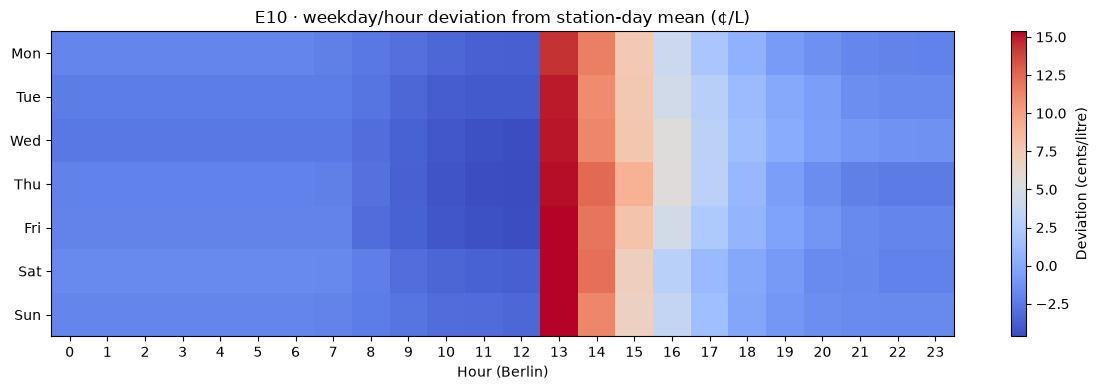

e10: lowest mean relative price: weekday=Thu, hour=12, -4.65¢
e10: highest mean relative price: weekday=Fri, hour=13, 15.37¢


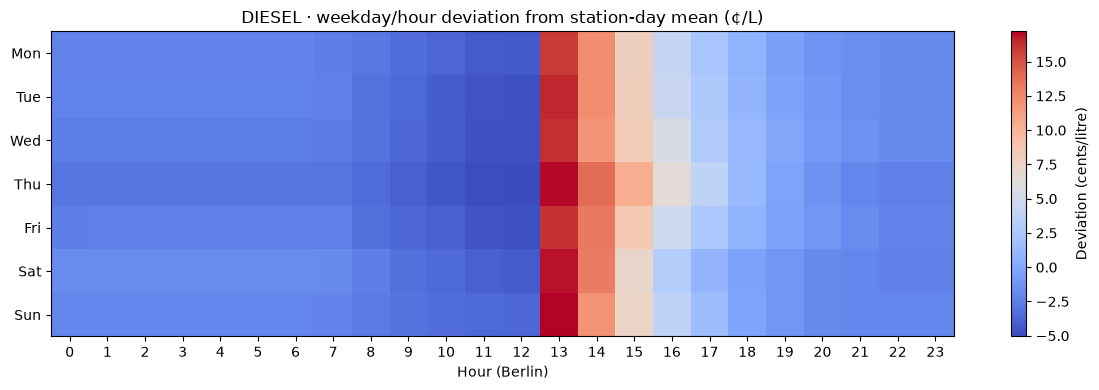

diesel: lowest mean relative price: weekday=Thu, hour=12, -5.06¢
diesel: highest mean relative price: weekday=Sun, hour=13, 17.21¢


In [11]:
weekday_short = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
for fuel in ["e10", "diesel"]:
    h = hourly[["station", "date", "weekday", "hour", fuel]].dropna().copy()
    h["daily_mean"] = h.groupby(["station", "date"])[fuel].transform("mean")
    h["deviation_cents"] = (h[fuel] - h["daily_mean"]) * 100
    h["dow"] = pd.to_datetime(h["date"]).dt.dayofweek
    pivot = h.groupby(["dow", "hour"])["deviation_cents"].mean().unstack("hour").reindex(index=range(7), columns=range(24))
    fig, ax = plt.subplots(figsize=(12, 4))
    im = ax.imshow(pivot.to_numpy(), aspect="auto", cmap="coolwarm")
    ax.set(xticks=range(24), yticks=range(7), yticklabels=weekday_short,
           xlabel="Hour (Berlin)", title=f"{fuel.upper()} · weekday/hour deviation from station-day mean (¢/L)")
    fig.colorbar(im, ax=ax, label="Deviation (cents/litre)")
    plt.tight_layout(); plt.show()
    extrema = pivot.stack().dropna()
    print(f"{fuel}: lowest mean relative price: weekday={weekday_short[extrema.idxmin()[0]]}, hour={extrema.idxmin()[1]}, {extrema.min():.2f}¢")
    print(f"{fuel}: highest mean relative price: weekday={weekday_short[extrema.idxmax()[0]]}, hour={extrema.idxmax()[1]}, {extrema.max():.2f}¢")

## Part 12 — Price increases by hour and monthly change


E10: total observed increases=608; at hour 12=607
DIESEL: total observed increases=606; at hour 12=606


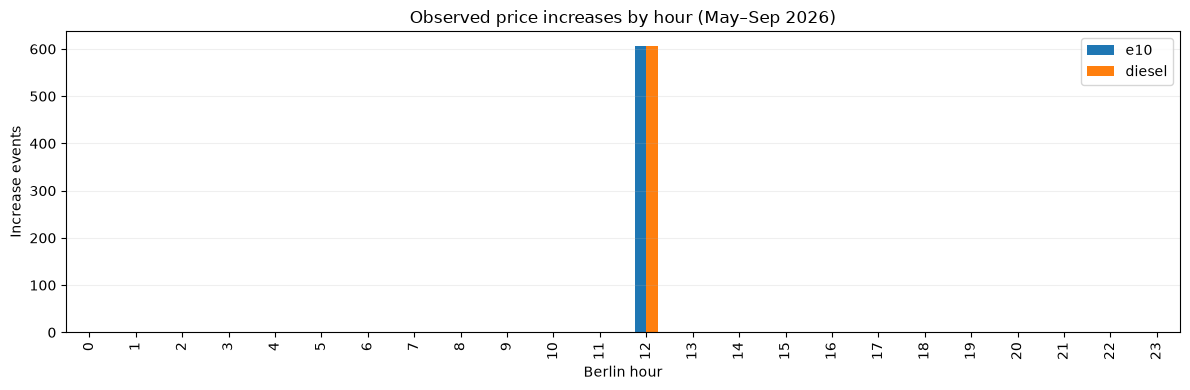

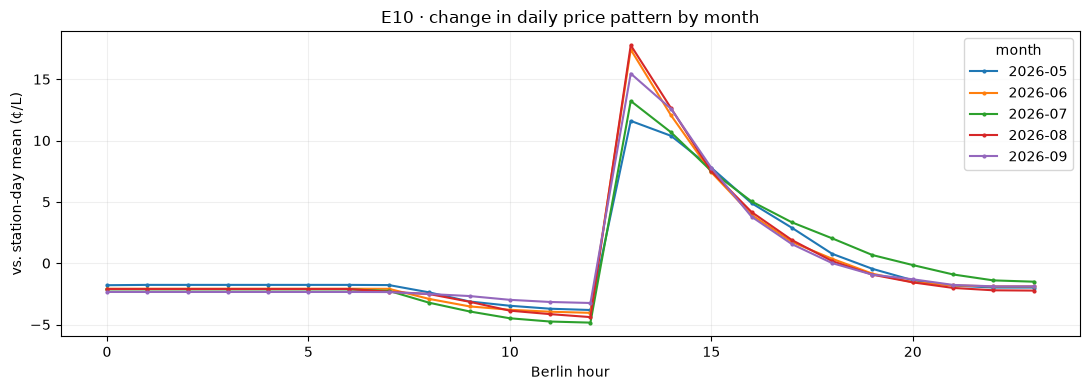

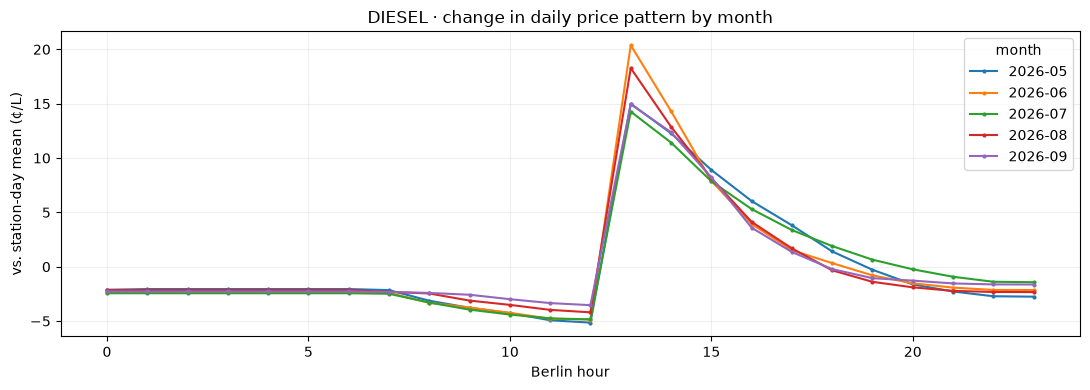

In [12]:
increase_frames = []
for fuel in ["e10", "diesel"]:
    g = prices[["station", "date", fuel]].sort_values(["station", "date"]).copy()
    g["previous_price"] = g.groupby("station")[fuel].shift()
    g = g[g["previous_price"].notna() & g[fuel].gt(0) & g["previous_price"].gt(0)]
    g["increased"] = g[fuel] > g["previous_price"]
    g["hour"] = g["date"].dt.hour
    counts = g.loc[g["increased"], "hour"].value_counts().reindex(range(24), fill_value=0).sort_index()
    increase_frames.append(counts.rename(fuel))
    print(f"{fuel.upper()}: total observed increases={int(counts.sum())}; at hour 12={int(counts.loc[12])}")
counts_by_hour = pd.concat(increase_frames, axis=1)
ax = counts_by_hour.plot.bar(figsize=(12, 4))
ax.set(title="Observed price increases by hour (May–Sep 2026)", xlabel="Berlin hour", ylabel="Increase events")
ax.grid(axis="y", alpha=.2)
plt.tight_layout(); plt.show()
# Detect whether the within-day pattern itself shifted over months.
for fuel in ["e10", "diesel"]:
    h = hourly[["station", "date", "hour", "month", fuel]].dropna().copy()
    h["relative_cents"] = (h[fuel] - h.groupby(["station", "date"])[fuel].transform("mean")) * 100
    monthly_pattern = h.groupby(["hour", "month"])["relative_cents"].mean().unstack("month")
    ax = monthly_pattern.plot(figsize=(11, 4), marker="o", markersize=2)
    ax.set(title=f"{fuel.upper()} · change in daily price pattern by month", xlabel="Berlin hour", ylabel="vs. station-day mean (¢/L)")
    ax.grid(alpha=.2); plt.tight_layout(); plt.show()

## Part 13 — Forecast min/max bands for a fixed snapshot

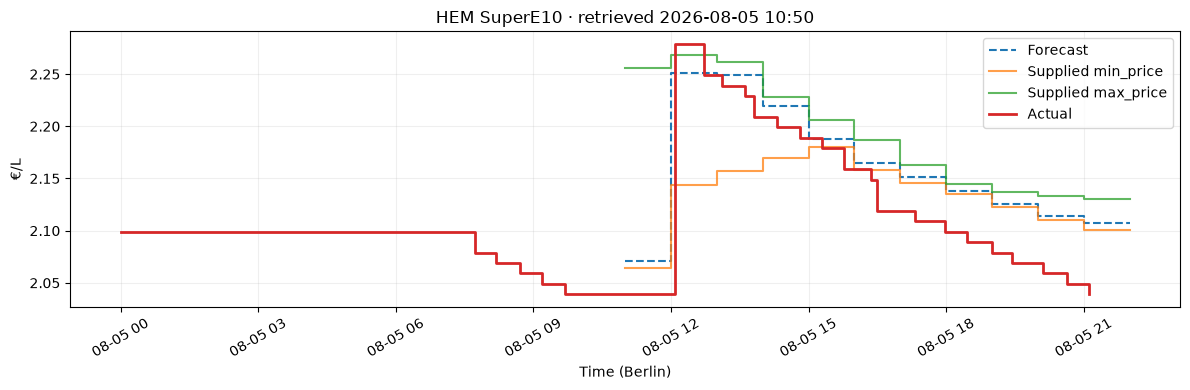

In [13]:
def plot_snapshot_with_bounds(station="HEM", fuel="SuperE10", day=PLOT_DAY):
    d0 = pd.Timestamp(day, tz=TZ)
    d1 = d0 + pd.DateOffset(days=1)
    f = forecasts[(forecasts.station == station) & (forecasts.fuel == fuel)
                  & forecasts.retrieved_at.ge(d0) & forecasts.retrieved_at.lt(d1)].copy()
    if f.empty:
        print(f"No retrieval for {station} {fuel} on {day}"); return
    retrieval = f.retrieved_at.min()
    f = f[(f.retrieved_at == retrieval) & f.target_at.ge(retrieval) & f.target_at.lt(d1)].sort_values("target_at")
    if f.empty:
        print("No same-day forecast targets"); return
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.step(f.target_at, f.price, where="post", label="Forecast", linestyle="--")
    if f.min_price.notna().any() and f.max_price.notna().any():
        ax.step(f.target_at, f.min_price, where="post", label="Supplied min_price", alpha=.75)
        ax.step(f.target_at, f.max_price, where="post", label="Supplied max_price", alpha=.75)
    actual_col = FUEL_MAP.get(fuel)
    if actual_col:
        prior = prices[(prices.station == station) & (prices.date < d0)][["date", actual_col]].tail(1)
        within = prices[(prices.station == station) & (prices.date >= d0) & (prices.date < d1)][["date", actual_col]]
        series = pd.concat([prior, within]).sort_values("date")
        if not series.empty:
            if not prior.empty:
                series = pd.concat([pd.DataFrame({"date": [d0], actual_col: [prior.iloc[-1][actual_col]]}), within])
            ax.step(series.date, series[actual_col], where="post", label="Actual", linewidth=2)
    ax.set(title=f"{station} {fuel} · retrieved {retrieval.strftime('%Y-%m-%d %H:%M')}", xlabel="Time (Berlin)", ylabel="€/L")
    ax.legend(); ax.grid(alpha=.2); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
plot_snapshot_with_bounds()

## Part 14 — Fair baseline: yesterday at the same Berlin-local time


Positive advantage: supplied forecast better than yesterday-same-time baseline.


n  forecast_MAE_cents  yesterday_MAE_cents  \
station fuel                                                     
ARAL    Diesel    222               4.208                3.059   
        SuperE10  222               3.651                2.896   
HEM     Diesel    222               5.096                3.680   
        SuperE10  222               4.492                3.441   
SHELL   Diesel    222               5.142                3.176   
        SuperE10  222               4.654                2.811   
STAR    Diesel    222               5.429                3.523   
        SuperE10  222               4.851                2.910   

                  forecast_advantage_cents  
station fuel                                
ARAL    Diesel                      -1.149  
        SuperE10                    -0.755  
HEM     Diesel                      -1.416  
        SuperE10                    -1.051  
SHELL   Diesel                      -1.967  
        SuperE10                    -1.843  
STAR    Diesel                      -1.907  
        SuperE10                    -1.941

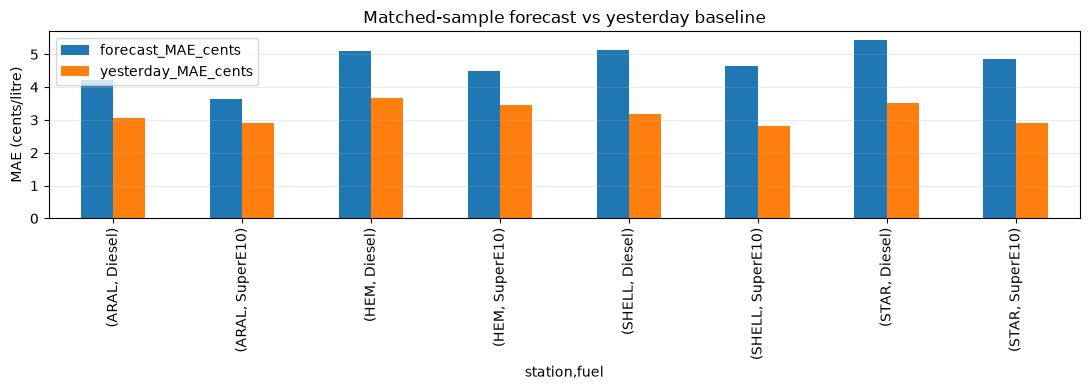

In [14]:
if evaluation.empty:
    print("No eligible comparisons for baseline.")
else:
    baseline_parts = []
    for (station, fuel), group in evaluation.groupby(["station", "fuel"]):
        col = FUEL_MAP[fuel]
        g = group.copy().sort_values("target_at")
        g["yesterday_at"] = g["target_at"] - pd.DateOffset(days=1)
        actual_events = prices.loc[prices.station.eq(station), ["date", col]].sort_values("date").rename(
            columns={"date": "baseline_event_at", col: "yesterday_price"})
        b = pd.merge_asof(g.sort_values("yesterday_at"), actual_events,
                          left_on="yesterday_at", right_on="baseline_event_at", direction="backward")
        baseline_parts.append(b)
    baseline_eval = pd.concat(baseline_parts, ignore_index=True).dropna(subset=["yesterday_price"]).copy()
    baseline_eval["baseline_abs_cents"] = (baseline_eval["yesterday_price"] - baseline_eval["actual_price"]).abs() * 100
    comparison_baseline = baseline_eval.groupby(["station", "fuel"]).agg(
        n=("target_at", "size"), forecast_MAE_cents=("abs_error_cents", "mean"),
        yesterday_MAE_cents=("baseline_abs_cents", "mean"))
    comparison_baseline["forecast_advantage_cents"] = comparison_baseline["yesterday_MAE_cents"] - comparison_baseline["forecast_MAE_cents"]
    print("Positive advantage: supplied forecast better than yesterday-same-time baseline.")
    display(comparison_baseline.round(3))
    ax = comparison_baseline[["forecast_MAE_cents", "yesterday_MAE_cents"]].plot.bar(figsize=(11, 4))
    ax.set(ylabel="MAE (cents/litre)", title="Matched-sample forecast vs yesterday baseline")
    ax.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()

## Part 15 — Forecast horizon accuracy 

,fuel,horizon_bin,n,MAE_cents
0,Diesel,0–1h,888,5.050
1,Diesel,1–2h,888,4.969
2,Diesel,2–3h,880,4.709
3,Diesel,3–6h,1060,4.114
4,Diesel,6–12h,1157,3.408
5,Diesel,12–24h,1840,4.794
6,Diesel,24–48h,2300,5.299
7,Diesel,48–168h,2638,6.051
8,SuperE10,0–1h,888,4.520
9,SuperE10,1–2h,888,4.412


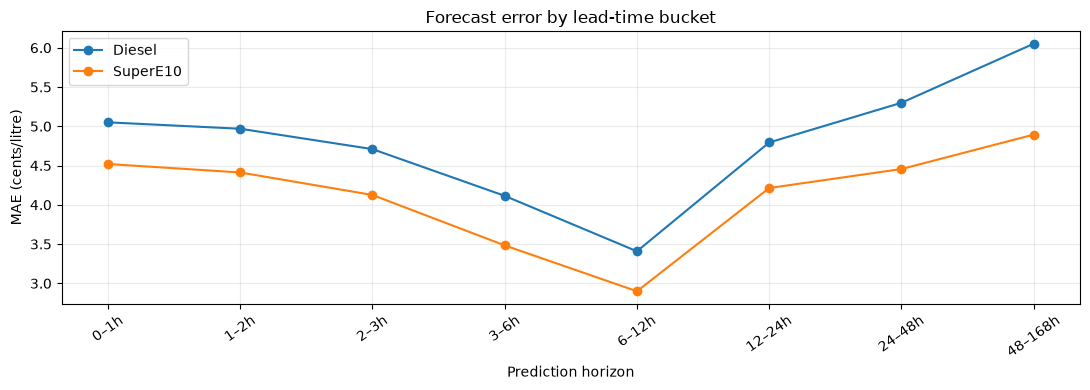

In [15]:
HORIZON_BINS = [0, 1, 2, 3, 6, 12, 24, 48, 168]
HORIZON_LABELS = ["0–1h", "1–2h", "2–3h", "3–6h", "6–12h", "12–24h", "24–48h", "48–168h"]
valid_h = forecasts.loc[forecasts.fuel.isin(FUEL_MAP)
                        & forecasts.target_at.ge(start_ts) & forecasts.target_at.lt(end_exclusive)
                        & forecasts.horizon_hours.gt(0)].copy()
valid_h["horizon_bin"] = pd.cut(valid_h.horizon_hours, bins=HORIZON_BINS,
                                 labels=HORIZON_LABELS, include_lowest=False, right=True)
valid_h = valid_h.dropna(subset=["horizon_bin"])
valid_h = valid_h.sort_values("retrieved_at").drop_duplicates(
    ["station", "fuel", "target_at", "horizon_bin"], keep="last")
parts_h = []
for (station, fuel), pred in valid_h.groupby(["station", "fuel"], observed=True):
    col = FUEL_MAP[fuel]
    ev = prices.loc[prices.station.eq(station), ["date", col]].sort_values("date").rename(
        columns={"date": "observed_at", col: "actual_price"})
    aligned = pd.merge_asof(pred.sort_values("target_at"), ev,
                            left_on="target_at", right_on="observed_at", direction="backward")
    parts_h.append(aligned)
if parts_h:
    horizon_eval = pd.concat(parts_h, ignore_index=True).dropna(subset=["actual_price"])
    horizon_eval["abs_error_cents"] = (horizon_eval.price - horizon_eval.actual_price).abs() * 100
    horizon_summary = horizon_eval.groupby(["fuel", "horizon_bin"], observed=True).agg(
        n=("abs_error_cents", "size"), MAE_cents=("abs_error_cents", "mean")).reset_index()
    display(horizon_summary.round(3))
    if not horizon_summary.empty:
        fig, ax = plt.subplots(figsize=(11, 4))
        for fuel, g in horizon_summary.groupby("fuel"):
            ax.plot(g.horizon_bin.astype(str), g.MAE_cents, marker="o", label=fuel)
        ax.set(ylabel="MAE (cents/litre)", xlabel="Prediction horizon", title="Forecast error by lead-time bucket")
        ax.legend(); ax.grid(alpha=.25); plt.xticks(rotation=35); plt.tight_layout(); plt.show()
else:
    print("No evaluable horizon bins within historical overlap.")

## Part 16 — Optional holiday comparison (NRW public holidays)

In [16]:
try:
    import holidays
except ImportError:
    print("Optional bonus skipped: install with python -m pip install holidays")
else:
    holiday_calendar = holidays.Germany(subdiv="NW", years=[2026])
    daily_prices = hourly.groupby(["station", "date", "month"], as_index=False)[["e10", "diesel"]].mean()
    daily_prices["is_public_holiday"] = daily_prices["date"].map(lambda x: x in holiday_calendar)
    print("Public holiday dates observed:", sorted(d for d in daily_prices.date.unique() if d in holiday_calendar))
    for fuel in ["e10", "diesel"]:
        h = daily_prices.groupby(["month", "is_public_holiday"])[fuel].agg(["mean", "count"]).reset_index()
        display(h.rename(columns={"mean": f"{fuel}_EUR_per_litre"}))
    print("Interpret descriptively only; no controlled causal inference and no school holiday analysis.")

Public holiday dates observed: [datetime.date(2026, 5, 1), datetime.date(2026, 5, 14), datetime.date(2026, 5, 25), datetime.date(2026, 6, 4)]


,month,is_public_holiday,e10_EUR_per_litre,count
0,2026-05,False,1.964729,112
1,2026-05,True,1.970872,12
2,2026-06,False,1.820394,116
3,2026-06,True,1.903271,4
4,2026-07,False,2.085935,124
5,2026-08,False,2.124252,124
6,2026-09,False,2.245465,120


,month,is_public_holiday,diesel_EUR_per_litre,count
0,2026-05,False,1.972065,112
1,2026-05,True,1.995196,12
2,2026-06,False,1.775476,116
3,2026-06,True,1.877229,4
4,2026-07,False,2.090579,124
5,2026-08,False,2.217814,124
6,2026-09,False,2.375701,120


Interpret descriptively only; no controlled causal inference and no school holiday analysis.


### Conclusions and limitations

The notebook calculates the final numeric results from your *local* data. Review the generated tables before submitting. Key points to discuss:

- **Price patterns:** Use the mean hour-by-station figures, weekday-hour heatmaps and price-increase counts below. Describe tendencies, not guaranteed cheapest hours. The observed 12:00 spike is compatible with the pricing rule, but the data alone cannot prove causation.
- **Forecast accuracy:** MAE in cents/litre is the primary error measure; RMSE emphasizes outliers and signed bias indicates overall over-/underprediction. The comparison uses only eligible forecasts within the selected horizon and overlapping actual-data dates—not the entire May–September period if forecast coverage is shorter.
- **Baseline:** Compare prediction and previous-day-same-local-time persistence *on exactly the same evaluable target points*, as done below. Lower MAE is better.
- **Forecast bands:** `min_price`/`max_price` are shown descriptively. Their semantic meaning has not been established, so do not claim calibrated statistical prediction intervals.
- **TruckDiesel:** Forecast data can contain TruckDiesel, but the historical Tankerkönig CSVs used here have no independently observed TruckDiesel price column. Do not substitute standard Diesel or report TruckDiesel error metrics.
- **Quality and limitations:** Station UUIDs match the four requested stations in the available September metadata snapshot; verification of station name/address/coordinate stability over all months requires additional snapshots. The `change=3` flag needs source documentation; this notebook does not infer its semantics. Prices before the earliest recorded event are unknown. The holiday analysis is associative, not causal.
- **Sharing:** Keep credentials, source forecast/historical datasets, and embedded raw-data outputs outside GitHub. Follow the professor's access restrictions.
